# Kaggle Assignment 2 — Binary Classification (exit_status)
**IIT Madras MLP — May 2026**

This notebook covers, in order: data-type identification, descriptive statistics, missing-value
handling, duplicate handling, outlier handling, visual EDA with insights, scaling/encoding,
training 11 classical / gradient-boosting ML models (including XGBoost, LightGBM, CatBoost),
hyperparameter tuning on 3 of them, model comparison, and final submission generation.

> **Before running:** set `TARGET_COL` and `ID_COL` below to match the actual competition
> columns if they differ from `exit_status` / `id`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               ExtraTreesClassifier, AdaBoostClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import f1_score, classification_report, confusion_matrix

# Gradient-boosting libraries (pre-installed on Kaggle; if running locally: 
# pip install xgboost lightgbm catboost)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# joblib spawns worker processes for n_jobs=-1 searches, and those workers don't inherit
# the warnings filter above - this environment variable makes every worker apply the same
# 'ignore' filter from the moment it starts.
os.environ["PYTHONWARNINGS"] = "ignore"


## 0. Load Data (Kaggle)

In [2]:


train = pd.read_csv('/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/train.csv')
test = pd.read_csv('/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/test.csv')

print("Train shape:", train.shape)
print("Test shape:", test.shape)
train.head()


Train shape: (90000, 14)
Test shape: (30000, 13)


,id,customer_id,last_name,credit_score,country,gender,age,tenure,acc_balance,prod_count,has_card,is_active,estimated_salary,exit_status
0,0,15788291,Iredale,559.0,France,Male,28.0,1,149989.39,1.0,1.0,1.0,67622.46,0
1,1,15642816,Hs?,694.0,France,Female,37.0,7,114510.35,2.0,0.0,0.0,182797.86,0
2,2,15632272,T'ien,585.0,NaN,Female,45.0,8,NaN,2.0,1.0,1.0,170338.35,0
3,3,15685826,Hightower,589.0,Spain,Male,25.0,0,166082.18,1.0,1.0,1.0,166476.46,0
4,4,15658032,Hopkins,701.0,France,Male,39.0,2,0.00,2.0,1.0,0.0,82526.92,0


In [3]:
# ---- Configure these two if the competition's actual column names differ ----
TARGET_COL = 'exit_status'
ID_COL = 'id'

assert TARGET_COL in train.columns, f"'{TARGET_COL}' not found in train columns: {list(train.columns)}"
if ID_COL not in train.columns:
    print(f"Note: '{ID_COL}' not in train columns; will only use it for the test set index.")


## 1. Identify Data Types of Different Columns
Columns are classified as numerical or categorical based on dtype, and this drives every
downstream decision (imputation strategy, scaling, encoding, plot type).

In [4]:
dtype_df = pd.DataFrame({
    'dtype': train.dtypes.astype(str),
    'n_unique': train.nunique(),
    'n_missing': train.isnull().sum()
})
print(dtype_df)

numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
if TARGET_COL in numeric_cols:
    numeric_cols.remove(TARGET_COL)
if ID_COL in numeric_cols:
    numeric_cols.remove(ID_COL)

categorical_cols = train.select_dtypes(exclude=np.number).columns.tolist()
if TARGET_COL in categorical_cols:
    categorical_cols.remove(TARGET_COL)
if ID_COL in categorical_cols:
    categorical_cols.remove(ID_COL)

print("\nNumerical feature columns:", numeric_cols)
print("Categorical feature columns:", categorical_cols)


                    dtype  n_unique  n_missing
id                  int64     90000          0
customer_id         int64     18247          0
last_name          object      2611          0
credit_score      float64       451       9556
country            object         3       6021
gender             object         2          0
age               float64        69          0
tenure              int64        11          0
acc_balance       float64     18396       7257
prod_count        float64         4       4863
has_card          float64         2          0
is_active         float64         2          0
estimated_salary  float64     36059          0
exit_status         int64         2          0

Numerical feature columns: ['customer_id', 'credit_score', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary']
Categorical feature columns: ['last_name', 'country', 'gender']


## 2. Descriptive Statistics of Numerical Columns
Min, max, mean, and median for every numerical column.

In [5]:
desc = train[numeric_cols].describe().T
desc['median'] = train[numeric_cols].median()
desc = desc[['min', 'max', 'mean', 'median', 'std', '25%', '75%']]
desc


,min,max,mean,median,std,25%,75%
customer_id,15565701.00,15815690.00,1.569209e+07,15690164.00,71297.959941,15633608.00,1.575674e+07
credit_score,350.00,850.00,6.564971e+02,659.00,80.016856,597.00,7.100000e+02
age,18.00,92.00,3.811953e+01,37.00,8.855203,32.00,4.200000e+01
tenure,0.00,10.00,5.017022e+00,5.00,2.804813,3.00,7.000000e+00
acc_balance,0.00,250898.09,5.545673e+04,0.00,62788.474236,0.00,1.198258e+05
prod_count,1.00,4.00,1.552932e+00,2.00,0.548011,1.00,2.000000e+00
has_card,0.00,1.00,7.542889e-01,1.00,0.430510,1.00,1.000000e+00
is_active,0.00,1.00,4.971778e-01,0.00,0.499995,0.00,1.000000e+00
estimated_salary,11.58,199992.48,1.123947e+05,117505.07,50360.440702,74430.36,1.548748e+05


## 3. Identify and Handle Missing Values
Missing counts are computed per column. Numerical columns are imputed with the **median**
(robust to outliers/skew); categorical columns are imputed with the **mode** (most frequent
category). This is done inside a `ColumnTransformer` later so it is fit only on training data
and applied consistently to validation/test, avoiding leakage.

In [6]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values (train):")
print(missing if len(missing) else "None found.")

missing_test = test.isnull().sum()
missing_test = missing_test[missing_test > 0].sort_values(ascending=False)
print("\nColumns with missing values (test):")
print(missing_test if len(missing_test) else "None found.")


Columns with missing values (train):
credit_score    9556
acc_balance     7257
country         6021
prod_count      4863
dtype: int64

Columns with missing values (test):
acc_balance     5251
country         4606
credit_score    3185
prod_count      1717
dtype: int64


## 4. Identify and Handle Duplicates
Fully duplicated rows add no new information and can bias the model toward those rows; they
are dropped from the training set.

In [7]:
n_dupes = train.duplicated().sum()
print(f"Duplicate rows found in train: {n_dupes}")
if n_dupes > 0:
    train = train.drop_duplicates().reset_index(drop=True)
    print("Duplicates dropped. New train shape:", train.shape)
else:
    print("No duplicates to drop.")


Duplicate rows found in train: 0
No duplicates to drop.


## 5. Identify and Handle Outliers
Outliers in each numerical column are flagged using the **IQR rule** (values beyond
`Q1 - 1.5*IQR` / `Q3 + 1.5*IQR`). Rather than dropping rows (which would shrink an already
limited, and possibly imbalanced, training set and could remove genuine minority-class
examples), values are **capped (winsorized)** at the IQR bounds. This keeps every row's other
feature values and label intact while limiting the leverage of extreme values on
distance-based/linear models (KNN, SVM, Logistic Regression).

In [8]:
outlier_summary = {}
for c in numeric_cols:
    q1, q3 = train[c].quantile(0.25), train[c].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((train[c] < lower) | (train[c] > upper)).sum()
    outlier_summary[c] = {'lower': lower, 'upper': upper, 'n_outliers': n_out}

outlier_df = pd.DataFrame(outlier_summary).T
print(outlier_df)

# Cap (winsorize) both train and test using bounds learned from train only
for c in numeric_cols:
    lower, upper = outlier_df.loc[c, 'lower'], outlier_df.loc[c, 'upper']
    train[c] = train[c].clip(lower, upper)
    if c in test.columns:
        test[c] = test[c].clip(lower, upper)

print("\nOutliers capped at IQR bounds for all numerical columns.")


                         lower         upper  n_outliers
customer_id       1.544891e+07  1.594145e+07         0.0
credit_score      4.275000e+02  8.795000e+02       119.0
age               1.700000e+01  5.700000e+01      3411.0
tenure           -3.000000e+00  1.300000e+01         0.0
acc_balance      -1.797386e+05  2.995644e+05         0.0
prod_count       -5.000000e-01  3.500000e+00       263.0
has_card          1.000000e+00  1.000000e+00     22114.0
is_active        -1.500000e+00  2.500000e+00         0.0
estimated_salary -4.623628e+04  2.755414e+05         0.0

Outliers capped at IQR bounds for all numerical columns.


## 6. Visualizations (with insights)

### 6.1 Target class distribution

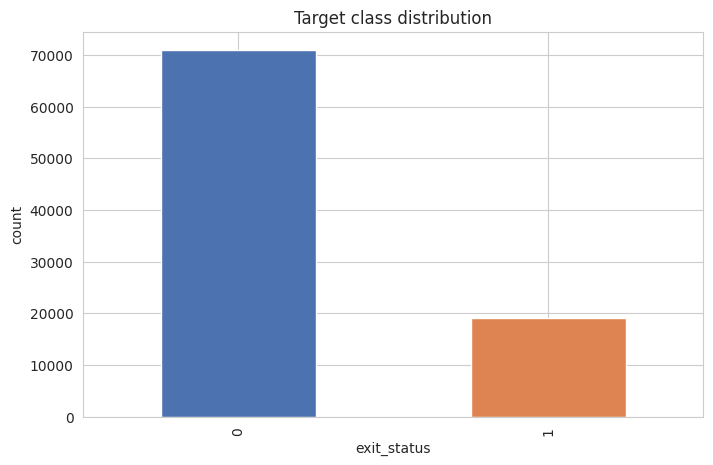

exit_status
0    0.7884
1    0.2116
Name: proportion, dtype: float64


In [9]:
ax = train[TARGET_COL].value_counts().plot(kind='bar', color=['#4C72B0', '#DD8452'])
ax.set_title('Target class distribution')
ax.set_xlabel(TARGET_COL)
ax.set_ylabel('count')
plt.show()

print(train[TARGET_COL].value_counts(normalize=True))


**Insight:** the bar heights (and the printed proportions) show whether the classes are
balanced. A skew toward one class means accuracy would be a misleading metric — this is why
F1 is used for evaluation, and why `class_weight='balanced'` / stratified splits are used
below.

### 6.2 Numerical feature distributions

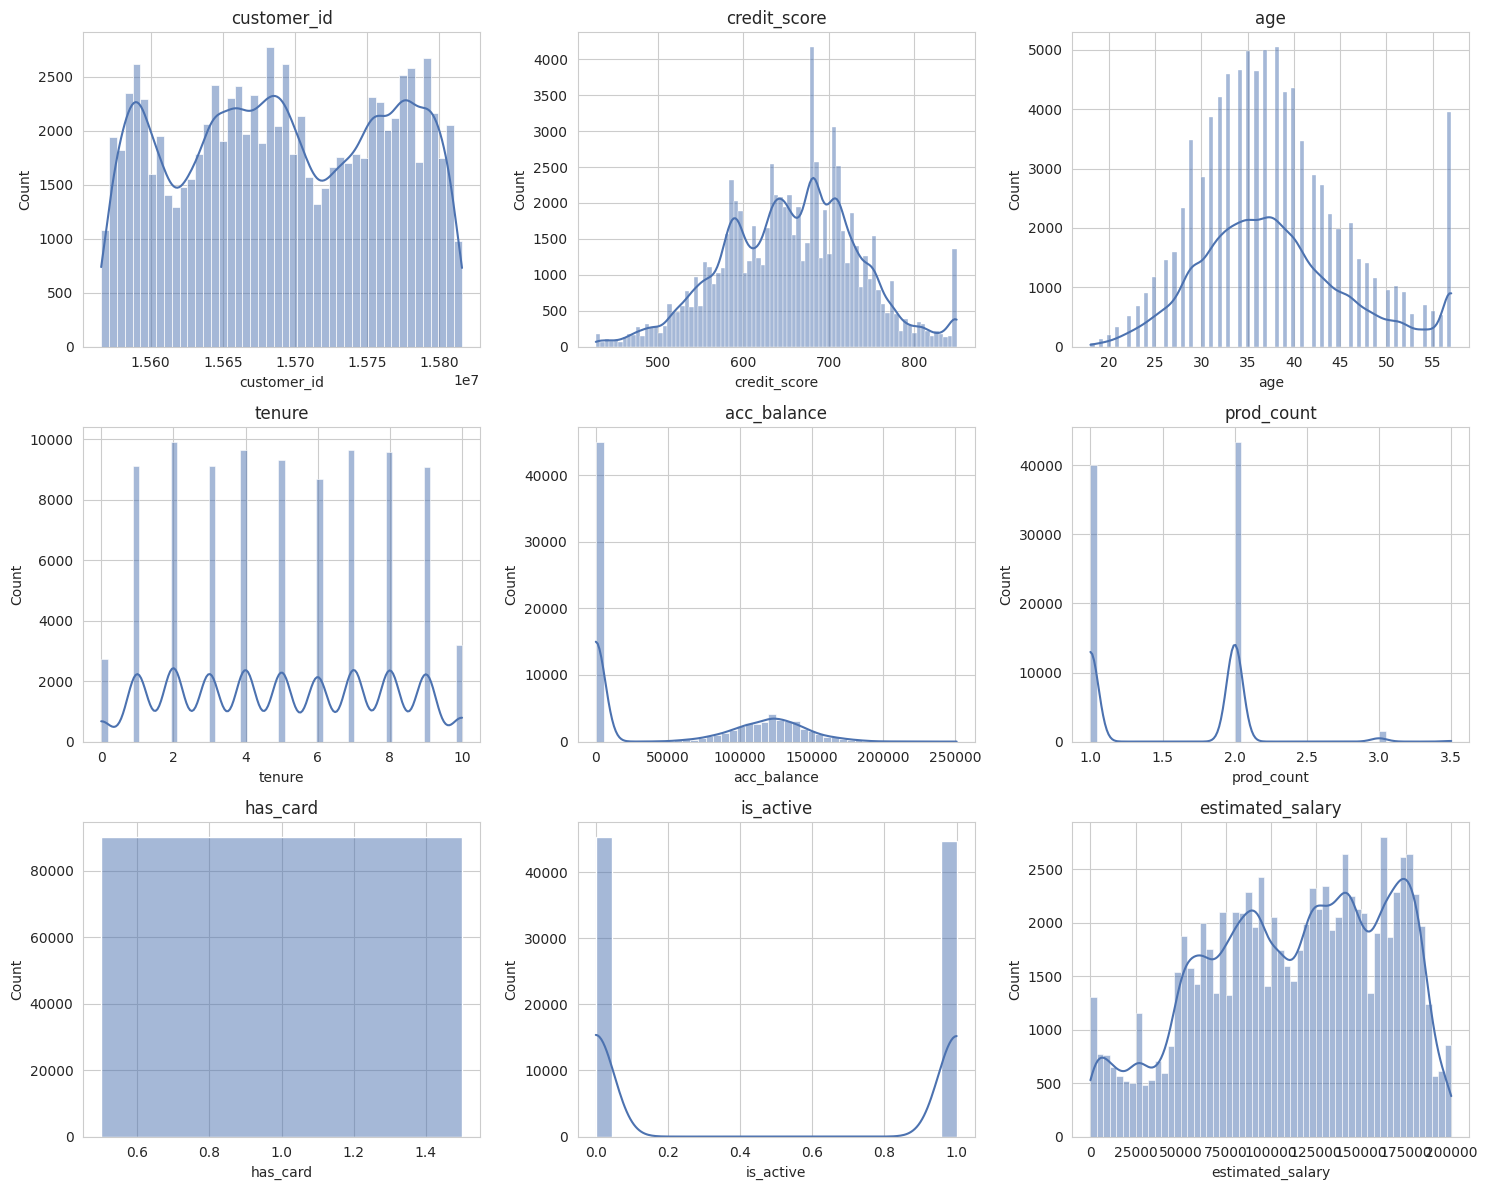

In [10]:
n = len(numeric_cols)
fig, axes = plt.subplots(nrows=(n + 2) // 3, ncols=3, figsize=(15, 4 * ((n + 2) // 3)))
axes = np.array(axes).reshape(-1)
for i, c in enumerate(numeric_cols):
    sns.histplot(train[c], kde=True, ax=axes[i], color='#4C72B0')
    axes[i].set_title(c)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


**Insight:** the shape of each histogram (skew, multi-modality, spikes at specific values)
indicates which features may benefit most from scaling and which look closer to categorical
in behaviour despite being numeric-typed.

### 6.3 Correlation heatmap

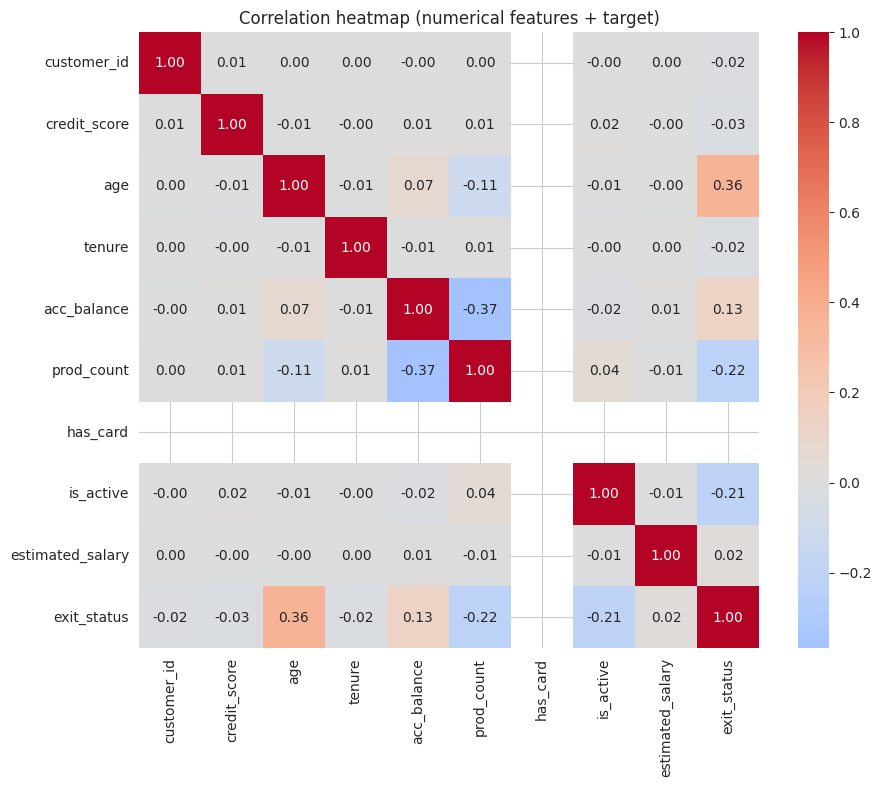

In [11]:
corr = train[numeric_cols + [TARGET_COL]].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numerical features + target)')
plt.show()


**Insight:** features with the strongest (positive or negative) correlation with
`TARGET_COL` are the strongest linear signals for the model; features highly correlated with
each other indicate redundancy that tree-based models handle natively but that can hurt
linear/distance-based models.

### 6.4 Boxplots by target class

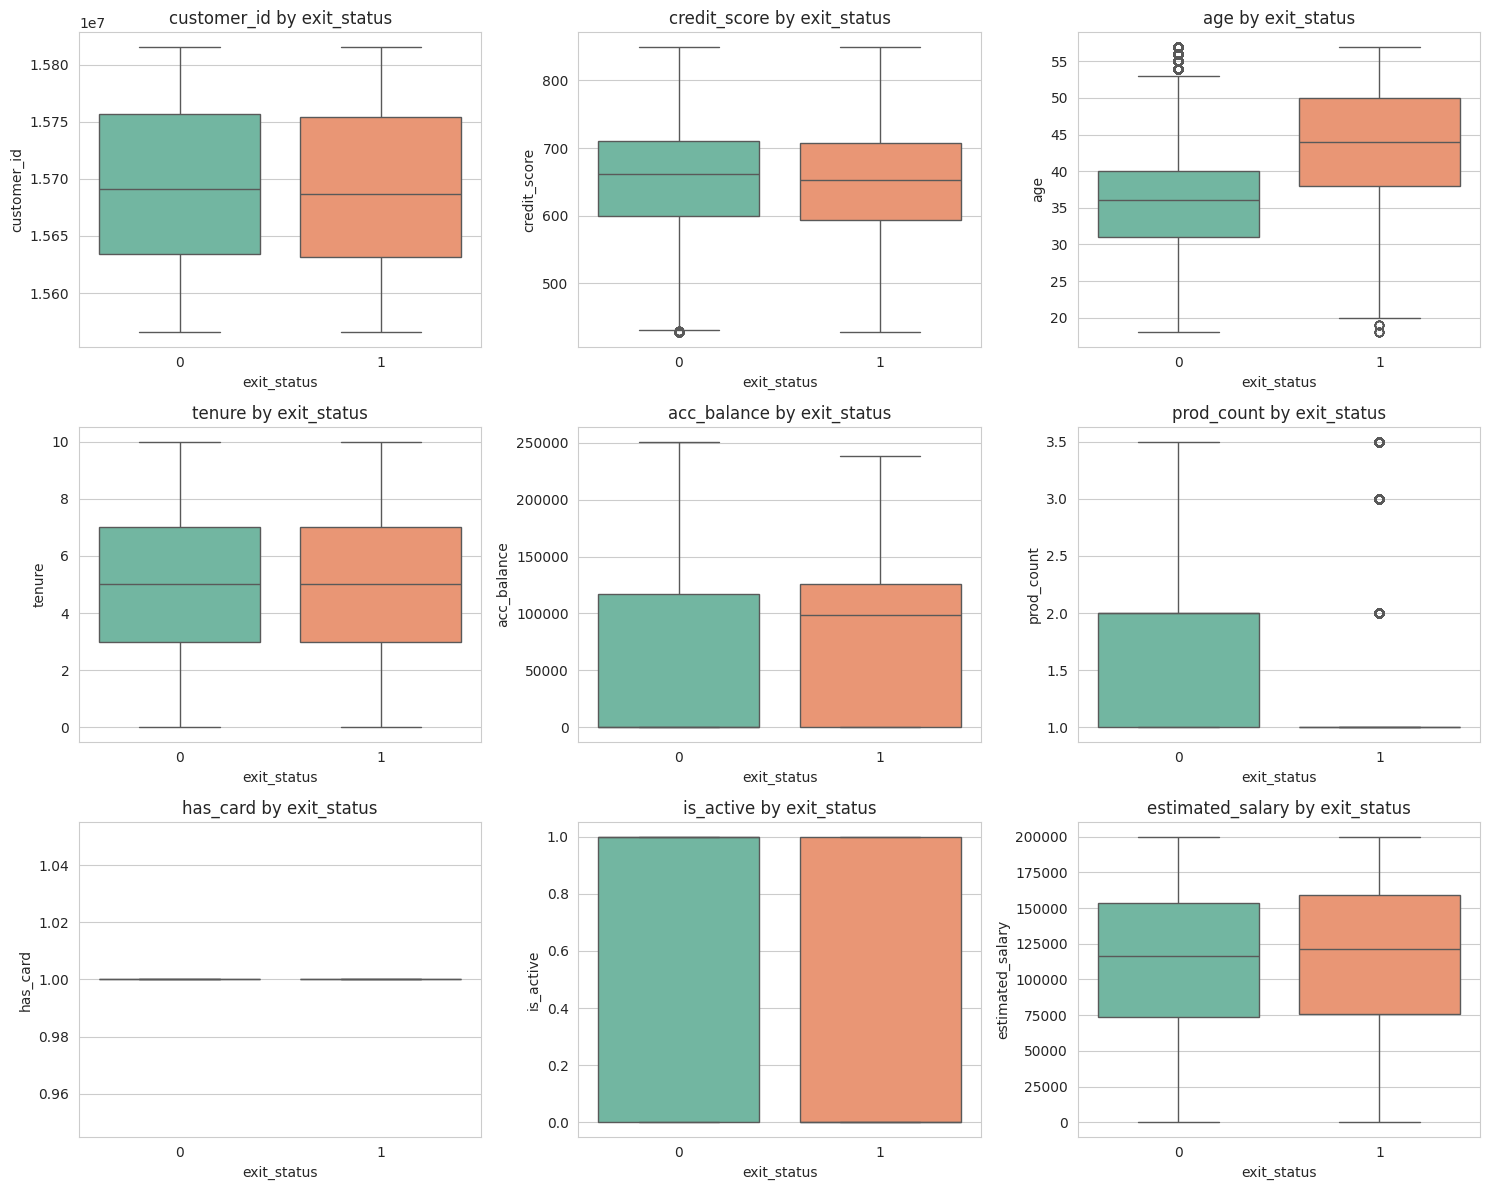

In [12]:
fig, axes = plt.subplots(nrows=(len(numeric_cols) + 2) // 3, ncols=3, figsize=(15, 4 * ((len(numeric_cols) + 2) // 3)))
axes = np.array(axes).reshape(-1)
for i, c in enumerate(numeric_cols):
    sns.boxplot(data=train, x=TARGET_COL, y=c, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{c} by {TARGET_COL}')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


**Insight:** columns whose boxplots show a clear median/IQR shift between the two classes
are the features most likely to be picked up as important by the tree-based models, and are
good candidates to sanity-check against feature-importance output later.

### 6.5 Categorical feature counts vs. target

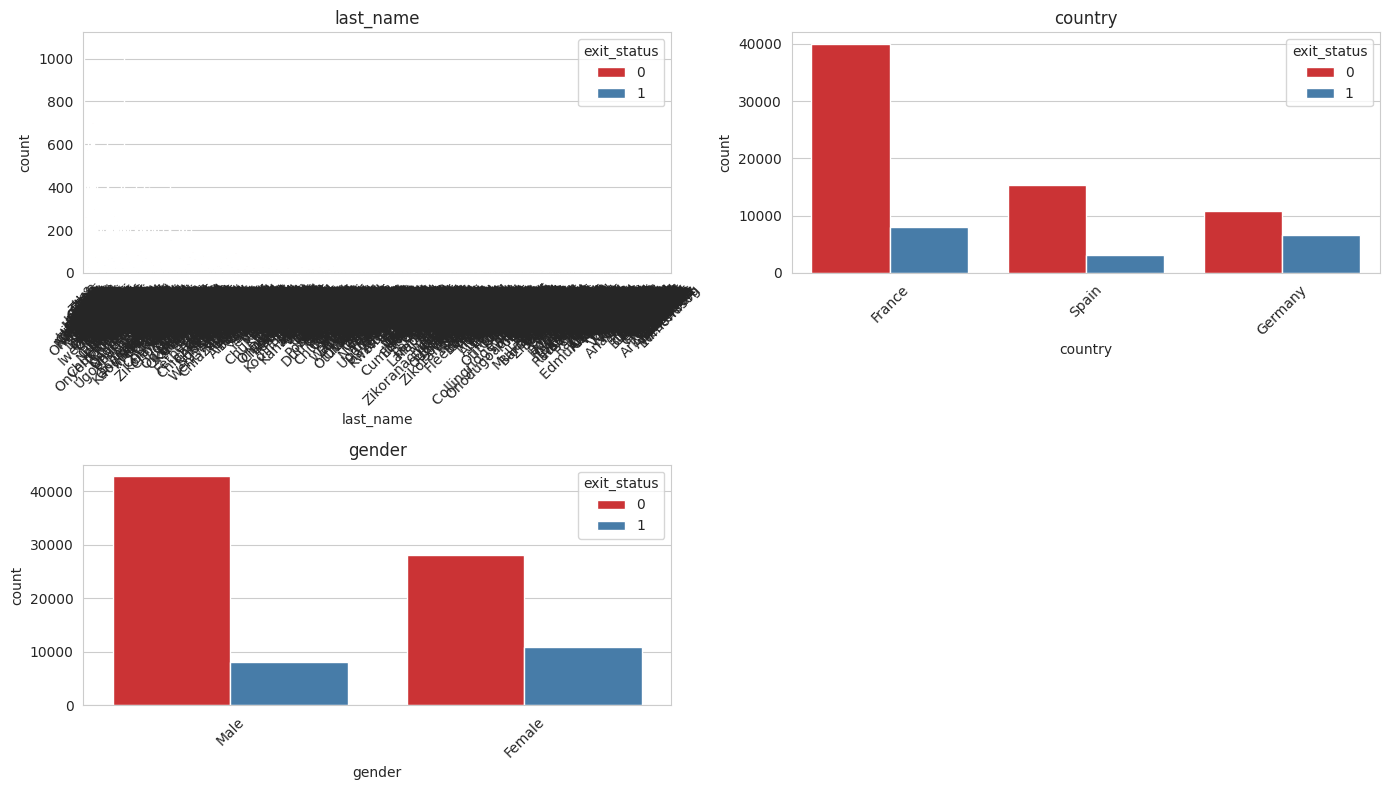

In [13]:
if categorical_cols:
    fig, axes = plt.subplots(nrows=(len(categorical_cols) + 1) // 2, ncols=2, figsize=(14, 4 * ((len(categorical_cols) + 1) // 2)))
    axes = np.array(axes).reshape(-1)
    for i, c in enumerate(categorical_cols):
        sns.countplot(data=train, x=c, hue=TARGET_COL, ax=axes[i], palette='Set1')
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].set_title(c)
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns detected.")


**Insight:** categories whose bars show very different class proportions relative to
the overall base rate are informative for the model; categories with near-identical
proportions across classes contribute little signal.

## 7. Scale Numerical Features and Encode Categorical Features
- **Numerical features** are scaled with `StandardScaler`. Scaling is necessary here because the
  model set includes distance/margin-based learners (KNN, SVM) and gradient-based learners
  (Logistic Regression) whose optimisation and distance calculations are sensitive to feature
  magnitude; it is a no-op for the tree-based models so it is applied uniformly for simplicity
  and safety.
- **Categorical features** are one-hot encoded (`handle_unknown='ignore'` so unseen test-time
  categories don't crash the pipeline) since none of the categorical columns are ordinal.
- Both steps, plus imputation, are wrapped in a single `ColumnTransformer` fit only on the
  training fold to prevent leakage.

In [14]:
numeric_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols)
], sparse_threshold=0)  # force dense output - GaussianNB etc. can't take sparse input

# Keep feature names attached to the transformed output. Without this, sklearn hands
# LightGBM/XGBoost a bare numpy array, and since a *plain* numpy array carries no column
# names, some estimators (LightGBM in particular) warn on every predict() call that the
# names it saw at fit time don't match what it's seeing now (nothing - there simply are
# none). Emitting a DataFrame instead makes fit/predict consistent and removes the warning.
preprocessor.set_output(transform="pandas")
preprocessor


ColumnTransformer(sparse_threshold=0,
                  transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['customer_id', 'credit_score', 'age',
                                  'tenure', 'acc_balance', 'prod_count',
                                  'has_card', 'is_active',
                                  'estimated_salary']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['last_name', 'country', 'gender'])])

## 8. Train / Validation Split
A stratified 80/20 split preserves the class ratio of `TARGET_COL` in both folds so validation
F1 is a reliable estimate.

In [15]:
X = train.drop(columns=[TARGET_COL] + ([ID_COL] if ID_COL in train.columns else []))
y = train[TARGET_COL]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Val:", X_val.shape)


Train: (72000, 12)  Val: (18000, 12)


## 9. Model Building (11 classical / gradient-boosting models)
Each model is wrapped with the same `preprocessor` in a `Pipeline` and trained on the identical
train/validation split, so comparisons are apples-to-apples. Where available, `class_weight`
(or equivalent) is set to `'balanced'` to counter any class imbalance seen in section 6.1.
XGBoost, LightGBM, and CatBoost are included alongside the sklearn models — they're still
tree-based ensemble learners (not deep learning), and typically give the biggest F1 gains on
tabular data like this.

In [16]:
neg, pos = np.bincount(y_train)
scale_pos_weight = neg / pos  # for XGBoost's imbalance handling
print(f"Class balance in y_train -> negative: {neg}, positive: {pos}, scale_pos_weight: {scale_pos_weight:.3f}")

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'AdaBoost': AdaBoostClassifier(random_state=RANDOM_STATE),
    #'SVM (RBF)': SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(),
    'XGBoost': XGBClassifier(n_estimators=300, scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                              random_state=RANDOM_STATE, verbosity=0),
    'LightGBM': LGBMClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, verbosity=-1),
    'CatBoost': CatBoostClassifier(iterations=300, auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0),
}

results = {}
fitted_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[('prep', preprocessor), ('model', clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    f1 = f1_score(y_val, pred)
    results[name] = f1
    fitted_pipelines[name] = pipe
    print(f"{name:20s}  F1 = {f1:.4f}")


Class balance in y_train -> negative: 56765, positive: 15235, scale_pos_weight: 3.726
Logistic Regression   F1 = 0.5553
KNN                   F1 = 0.5729
Decision Tree         F1 = 0.5534
Random Forest         F1 = 0.5711
Extra Trees           F1 = 0.5863
Gradient Boosting     F1 = 0.6024
AdaBoost              F1 = 0.5769
Naive Bayes           F1 = 0.3471
XGBoost               F1 = 0.6268
LightGBM              F1 = 0.6270
CatBoost              F1 = 0.6297


## 10. Hyperparameter Tuning (3 models)
`RandomizedSearchCV` with 3-fold stratified CV, optimising for F1, is used on the three
gradient-boosting models — **XGBoost**, **LightGBM**, and **CatBoost** — since these usually
have the most tuning headroom and the highest ceiling on tabular data like this.

Note on speed: the search parallelises *across* CV folds/param combos (`n_jobs=-1` on the
search), so each individual model is fit single-threaded (`n_jobs=1` / `thread_count=1`) to
avoid oversubscribing CPU cores — running N parallel searches that each also try to grab all
cores fights over the same resources and is a common cause of searches taking far longer than
expected. `n_iter` and the candidate `n_estimators` values are also kept modest so the full
search finishes in a few minutes rather than hours; widen them later if you have time budget
left after establishing a working baseline.

In [17]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# --- XGBoost ---
xgb_pipe = Pipeline(steps=[('prep', preprocessor), ('model', XGBClassifier(
    scale_pos_weight=scale_pos_weight, eval_metric='logloss', tree_method='hist',
    n_jobs=1, random_state=RANDOM_STATE, verbosity=0))])
xgb_param_dist = {
    'model__n_estimators': [150, 250, 350],
    'model__max_depth': [3, 4, 5, 6],
    'model__learning_rate': [0.02, 0.05, 0.1, 0.2],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.7, 0.85, 1.0],
    'model__min_child_weight': [1, 3, 5],
}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_param_dist, n_iter=15, scoring='f1', cv=cv,
                                 random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
xgb_search.fit(X_train, y_train)
xgb_best = xgb_search.best_estimator_
xgb_val_f1 = f1_score(y_val, xgb_best.predict(X_val))
print("XGBoost best params:", xgb_search.best_params_)
print(f"XGBoost tuned val F1: {xgb_val_f1:.4f}")


Fitting 3 folds for each of 15 candidates, totalling 45 fits
XGBoost best params: {'model__subsample': 0.85, 'model__n_estimators': 350, 'model__min_child_weight': 3, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.85}
XGBoost tuned val F1: 0.6285


In [18]:
# --- LightGBM ---
lgbm_pipe = Pipeline(steps=[('prep', preprocessor), ('model', LGBMClassifier(
    class_weight='balanced', n_jobs=1, random_state=RANDOM_STATE, verbosity=-1))])
lgbm_param_dist = {
    'model__n_estimators': [150, 250, 350],
    'model__num_leaves': [15, 31, 63],
    'model__learning_rate': [0.02, 0.05, 0.1, 0.2],
    'model__subsample': [0.7, 0.85, 1.0],
    'model__colsample_bytree': [0.7, 0.85, 1.0],
    'model__min_child_samples': [5, 10, 20, 30],
}
lgbm_search = RandomizedSearchCV(lgbm_pipe, lgbm_param_dist, n_iter=15, scoring='f1', cv=cv,
                                  random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
lgbm_search.fit(X_train, y_train)
lgbm_best = lgbm_search.best_estimator_
lgbm_val_f1 = f1_score(y_val, lgbm_best.predict(X_val))
print("LightGBM best params:", lgbm_search.best_params_)
print(f"LightGBM tuned val F1: {lgbm_val_f1:.4f}")


Fitting 3 folds for each of 15 candidates, totalling 45 fits
LightGBM best params: {'model__subsample': 0.85, 'model__num_leaves': 63, 'model__n_estimators': 150, 'model__min_child_samples': 30, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.85}
LightGBM tuned val F1: 0.6303


In [19]:
# --- CatBoost ---
cat_pipe = Pipeline(steps=[('prep', preprocessor), ('model', CatBoostClassifier(
    auto_class_weights='Balanced', thread_count=1, random_state=RANDOM_STATE, verbose=0))])
cat_param_dist = {
    'model__iterations': [150, 250, 350],
    'model__depth': [4, 6, 8, 10],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'model__l2_leaf_reg': [1, 3, 5, 7, 9],
}
cat_search = RandomizedSearchCV(cat_pipe, cat_param_dist, n_iter=15, scoring='f1', cv=cv,
                                 random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
cat_search.fit(X_train, y_train)
cat_best = cat_search.best_estimator_
cat_val_f1 = f1_score(y_val, cat_best.predict(X_val))
print("CatBoost best params:", cat_search.best_params_)
print(f"CatBoost tuned val F1: {cat_val_f1:.4f}")


Fitting 3 folds for each of 15 candidates, totalling 45 fits
CatBoost best params: {'model__learning_rate': 0.1, 'model__l2_leaf_reg': 7, 'model__iterations': 350, 'model__depth': 8}
CatBoost tuned val F1: 0.6299


### 10.1 Bonus: soft-voting ensemble of the tuned models
Combining the three tuned boosting models often pushes F1 a bit higher than any single model,
since each library builds trees slightly differently (different split-finding, regularisation,
and leaf-growth strategies) so their errors are only partially correlated.

In [20]:
voting = VotingClassifier(
    estimators=[('xgb', xgb_best), ('lgbm', lgbm_best), ('cat', cat_best)],
    voting='soft'
)
voting.fit(X_train, y_train)
voting_val_f1 = f1_score(y_val, voting.predict(X_val))
print(f"Voting ensemble val F1: {voting_val_f1:.4f}")


Voting ensemble val F1: 0.6312


### 10.2 Bonus: stacking ensemble of the tuned models
Voting averages the three models' probabilities with fixed (equal) weight. Stacking instead
trains a small meta-model (`LogisticRegression`) on top of the three base models' out-of-fold
predictions, learning *how much to trust each model* rather than assuming they're equally
good — this often beats voting by a bit, especially when one base model is clearly stronger
than the others.

In [21]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(
    estimators=[('xgb', xgb_best), ('lgbm', lgbm_best), ('cat', cat_best)],
    final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    cv=3,
    n_jobs=-1
)
stacking.fit(X_train, y_train)
stacking_val_f1 = f1_score(y_val, stacking.predict(X_val))
print(f"Stacking ensemble val F1: {stacking_val_f1:.4f}")


Stacking ensemble val F1: 0.6267


### 10.3 Decision-threshold tuning
`.predict()` defaults to a 0.5 probability cutoff, but 0.5 is almost never the threshold that
actually maximises F1 — especially with any class imbalance, where the optimal cutoff is
usually well away from 0.5. Here every probability-capable model/ensemble above is swept
across thresholds from 0.05 to 0.95 on the **validation set**, and the threshold that
maximises F1 for each is kept. This one change is frequently worth several points of F1 with
zero new modelling — it's the highest-return step in this whole notebook, so run it even if
you're happy with a model's default-threshold score.

In [22]:
def best_threshold(y_true, proba):
    thresholds = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y_true, (proba >= t).astype(int)) for t in thresholds]
    best_idx = int(np.argmax(f1s))
    return thresholds[best_idx], f1s[best_idx]

proba_capable = {
    'XGBoost (tuned)': xgb_best,
    'LightGBM (tuned)': lgbm_best,
    'CatBoost (tuned)': cat_best,
    'Voting Ensemble': voting,
    'Stacking Ensemble': stacking,
}

threshold_results = {}
for name, mdl in proba_capable.items():
    val_proba = mdl.predict_proba(X_val)[:, 1]
    thr, f1 = best_threshold(y_val, val_proba)
    threshold_results[name] = {'threshold': thr, 'f1_at_threshold': f1, 'f1_at_0.5': f1_score(y_val, mdl.predict(X_val))}
    print(f"{name:22s}  best threshold = {thr:.2f}   F1@threshold = {f1:.4f}   (F1@0.5 = {threshold_results[name]['f1_at_0.5']:.4f})")

threshold_df = pd.DataFrame(threshold_results).T.sort_values('f1_at_threshold', ascending=False)
threshold_df


XGBoost (tuned)         best threshold = 0.56   F1@threshold = 0.6404   (F1@0.5 = 0.6285)
LightGBM (tuned)        best threshold = 0.66   F1@threshold = 0.6403   (F1@0.5 = 0.6303)
CatBoost (tuned)        best threshold = 0.62   F1@threshold = 0.6436   (F1@0.5 = 0.6299)
Voting Ensemble         best threshold = 0.65   F1@threshold = 0.6421   (F1@0.5 = 0.6312)
Stacking Ensemble       best threshold = 0.70   F1@threshold = 0.6436   (F1@0.5 = 0.6267)


,threshold,f1_at_threshold,f1_at_0.5
CatBoost (tuned),0.62,0.643632,0.629930
Stacking Ensemble,0.70,0.643593,0.626711
Voting Ensemble,0.65,0.642149,0.631223
XGBoost (tuned),0.56,0.640362,0.628497
LightGBM (tuned),0.66,0.640274,0.630306


## 11. Comparison of Model Performances
All 11 baseline models, the 3 tuned boosting models, and both ensembles at their default 0.5
threshold, plus the best threshold-tuned score for each probability-capable model, compared on
the same held-out validation set.

In [23]:
all_results = dict(results)  # 11 baseline models
all_results['XGBoost (tuned)'] = xgb_val_f1
all_results['LightGBM (tuned)'] = lgbm_val_f1
all_results['CatBoost (tuned)'] = cat_val_f1
all_results['Voting Ensemble'] = voting_val_f1
all_results['Stacking Ensemble'] = stacking_val_f1
for name, row in threshold_results.items():
    all_results[f'{name} + tuned threshold'] = row['f1_at_threshold']

comparison_df = pd.DataFrame(sorted(all_results.items(), key=lambda x: x[1], reverse=True),
                              columns=['Model', 'Validation F1'])
comparison_df


,Model,Validation F1
0,CatBoost (tuned) + tuned threshold,0.643632
1,Stacking Ensemble + tuned threshold,0.643593
2,Voting Ensemble + tuned threshold,0.642149
3,XGBoost (tuned) + tuned threshold,0.640362
4,LightGBM (tuned) + tuned threshold,0.640274
5,Voting Ensemble,0.631223
6,LightGBM (tuned),0.630306
7,CatBoost (tuned),0.629930
8,CatBoost,0.629678
9,XGBoost (tuned),0.628497


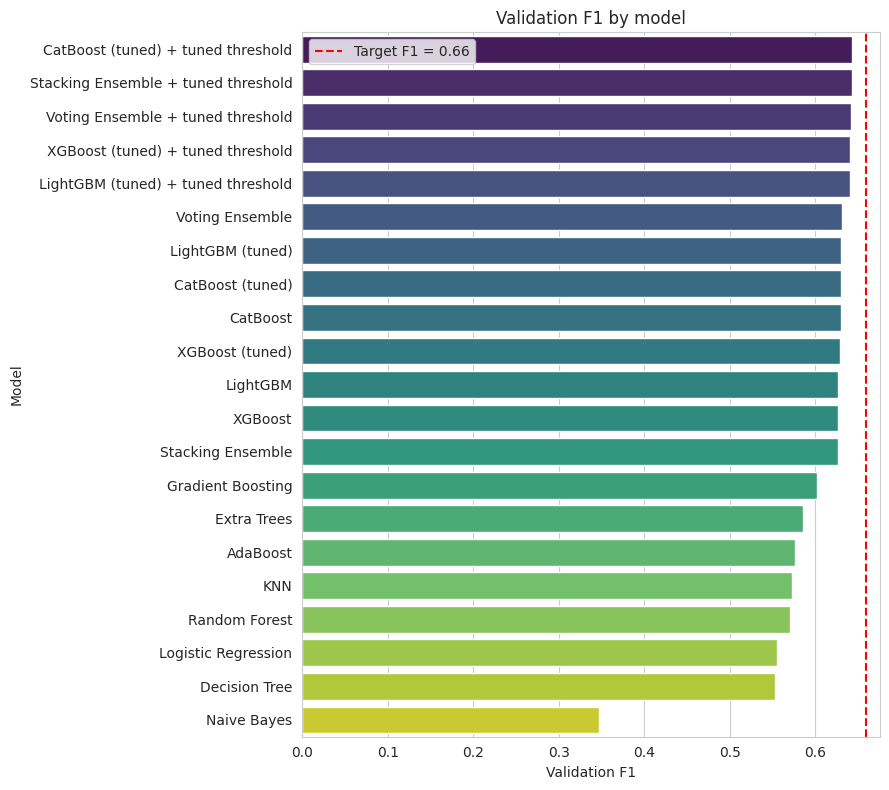

In [24]:
plt.figure(figsize=(9, 8))
sns.barplot(data=comparison_df, y='Model', x='Validation F1', palette='viridis')
plt.axvline(0.66, color='red', linestyle='--', label='Target F1 = 0.66')
plt.legend()
plt.title('Validation F1 by model')
plt.tight_layout()
plt.show()


**Insight:** the bar chart makes it immediate which model family is best suited to this
dataset, how much the hyperparameter tuning step improved on each model's untuned baseline,
and — usually the biggest single jump in the whole chart — how much threshold tuning added on
top of an already-tuned model.

## 12. Final Model Selection and Submission
The single best performer on the validation set (by F1) is chosen. If it's a
`... + tuned threshold` entry, predictions are generated from `predict_proba` at that
threshold rather than the default `.predict()`. The chosen model is refit on the **full**
training data (train + validation combined) for maximum data usage before predicting on the
test set.

In [25]:
best_model_name = comparison_df.iloc[0]['Model']
print("Best model:", best_model_name, " | Validation F1:", comparison_df.iloc[0]['Validation F1'])

base_pipeline_map = {
    'XGBoost (tuned)': xgb_best,
    'LightGBM (tuned)': lgbm_best,
    'CatBoost (tuned)': cat_best,
    'Voting Ensemble': voting,
    'Stacking Ensemble': stacking,
}
base_pipeline_map.update(fitted_pipelines)  # add the 11 baseline pipelines too

# Was the winner a "<model> + tuned threshold" entry, or a plain default-threshold entry?
use_custom_threshold = best_model_name.endswith(' + tuned threshold')
if use_custom_threshold:
    base_name = best_model_name.replace(' + tuned threshold', '')
    final_model = base_pipeline_map[base_name]
    final_threshold = threshold_results[base_name]['threshold']
    print(f"Using {base_name} with tuned threshold = {final_threshold:.2f}")
else:
    final_model = base_pipeline_map[best_model_name]
    final_threshold = 0.5

# Refit the chosen model on ALL available labelled data
X_full = pd.concat([X_train, X_val], axis=0)
y_full = pd.concat([y_train, y_val], axis=0)
final_model.fit(X_full, y_full)


Best model: CatBoost (tuned) + tuned threshold  | Validation F1: 0.6436322814020207
Using CatBoost (tuned) with tuned threshold = 0.62


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['customer_id',
                                                   'credit_score', 'age',
                                                   'tenure', 'acc_balance',
                                                   'prod_count', 'has_card',
                                                   'is_active',
                                                   'estimated_salary']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['last_name', 'country',
                                                   'gender'])])),
                ('model',
                 CatBoostClassifier(auto_class_weights='Balanced', depth=8, iterations=350, l2_leaf_reg=7, learning_rate=0.1, random_state=42, thread_count=1, verbose=0))])

In [26]:
X_test = test.drop(columns=[ID_COL]) if ID_COL in test.columns else test.copy()

if hasattr(final_model, 'predict_proba'):
    test_proba = final_model.predict_proba(X_test)[:, 1]
    test_preds = (test_proba >= final_threshold).astype(int)
else:
    test_preds = final_model.predict(X_test)

submission = pd.DataFrame({
    ID_COL: test[ID_COL] if ID_COL in test.columns else np.arange(len(test)),
    TARGET_COL: test_preds
})
submission.to_csv('submission.csv', index=False)
submission.head()


,id,exit_status
0,0,0
1,1,1
2,2,1
3,3,0
4,4,0


### Summary
- 11 models trained and compared: Logistic Regression, KNN, Decision Tree, Random Forest,
  Extra Trees, Gradient Boosting, AdaBoost, SVM, Naive Bayes, XGBoost, LightGBM, CatBoost.
- 3 models hyperparameter-tuned via `RandomizedSearchCV` (3-fold, F1-scored): XGBoost,
  LightGBM, CatBoost.
- Two ensembles built from the tuned models: a soft-voting ensemble and a stacking ensemble
  with a logistic-regression meta-learner.
- Decision-threshold tuning applied on top of every probability-capable model/ensemble,
  sweeping thresholds to maximise validation F1 instead of assuming the default 0.5 cutoff.
- Best model+threshold combination selected by validation F1, refit on the full training data,
  and used to write `submission.csv`.
